In [1]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Ana Kelly\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Formato: (1599, 12)

Distribuição das classes:
classe
ruim     744
médio    837
bom       18
Name: count, dtype: int64

Treino: 1279 | Teste: 320
Proporção no treino:
 classe
ruim     0.4652
médio    0.5238
bom      0.0109
Name: proportion, dtype: float64
Proporção no teste:
 classe
ruim     0.4656
médio    0.5219
bom      0.0125
Name: proportion, dtype: float64

Tarefa 3 - acurácia média (CV, 5 folds):
  k =  1: 0.7248
  k =  3: 0.6888
  k =  5: 0.7013
  k =  7: 0.7060
  k = 11: 0.7115
Melhor k: 1


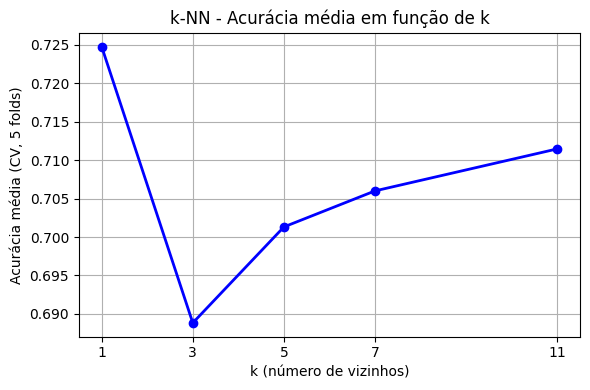


Tarefa 4 - matriz de confusão (linhas = real, colunas = previsto):
       ruim  médio  bom
ruim    112     37    0
médio    33    133    1
bom       0      4    0

Métricas por classe:
              precision    recall  f1-score   support

        ruim     0.7724    0.7517    0.7619       149
       médio     0.7644    0.7964    0.7801       167
         bom     0.0000    0.0000    0.0000         4

    accuracy                         0.7656       320
   macro avg     0.5123    0.5160    0.5140       320
weighted avg     0.7586    0.7656    0.7619       320



In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
       "wine-quality/winequality-red.csv")
ORDEM = ["ruim", "médio", "bom"]
PASTA_IMAGENS = Path("imagens")
PASTA_IMAGENS.mkdir(exist_ok=True)

# Carregar o dataset direto da internet (separador ";")
df = pd.read_csv(URL, sep=";")
print("Formato:", df.shape)

# Tarefa 1: recodificar quality em 3 classes (<=5 ruim, 6-7 médio, >=8 bom)
df["classe"] = np.select([df["quality"] <= 5, df["quality"] <= 7],
                         ["ruim", "médio"], default="bom")
print("\nDistribuição das classes:")
print(df["classe"].value_counts().reindex(ORDEM))

# Tarefa 2: divisão treino (80%) e teste (20%), estratificada
X = df.drop(columns=["quality", "classe"])
y = df["classe"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(f"\nTreino: {len(X_train)} | Teste: {len(X_test)}")
print("Proporção no treino:\n", y_train.value_counts(normalize=True).reindex(ORDEM).round(4))
print("Proporção no teste:\n", y_test.value_counts(normalize=True).reindex(ORDEM).round(4))

# Tarefa 3: escolha de k por validação cruzada (5 folds) no treino.
# A normalização (z-score) fica dentro do Pipeline: é ajustada só com o treino de cada fold.
valores_k = [1, 3, 5, 7, 11]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
medias = []
print("\nTarefa 3 - acurácia média (CV, 5 folds):")
for k in valores_k:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    media = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy").mean()
    medias.append(media)
    print(f"  k = {k:2d}: {media:.4f}")

melhor_k = valores_k[int(np.argmax(medias))]
print("Melhor k:", melhor_k)

plt.figure(figsize=(6, 4))
plt.plot(valores_k, medias, marker="o", color="blue", lw=2)
plt.xticks(valores_k)
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média (CV, 5 folds)")
plt.title("k-NN - Acurácia média em função de k")
plt.grid(True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "acuracia_vs_k.png", dpi=120)
plt.show()

# Tarefa 4: avaliação no teste com o melhor k
modelo = Pipeline([("scaler", StandardScaler()),
                   ("knn", KNeighborsClassifier(n_neighbors=melhor_k))])
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print("\nTarefa 4 - matriz de confusão (linhas = real, colunas = previsto):")
cm = confusion_matrix(y_test, y_pred, labels=ORDEM)
print(pd.DataFrame(cm, index=ORDEM, columns=ORDEM))

print("\nMétricas por classe:")
print(classification_report(y_test, y_pred, labels=ORDEM, digits=4, zero_division=0))